<div dir="rtl" style="text-align: right;">
# سیستم پیشنهاد فیلم با استفاده از KNN و PCA

## ۱. معرفی پروژه

هدف این پروژه طراحی یک سیستم پیشنهاد فیلم با استفاده از روش‌های یادگیری ماشین است. در این پروژه از تکنیک **User-Based Collaborative Filtering** استفاده می‌کنیم؛ به این صورت که ابتدا کاربران با سلیقه‌ی مشابه را شناسایی می‌کنیم و سپس بر اساس امتیازهای آن‌ها، فیلم‌هایی را به کاربران پیشنهاد می‌دهیم.

در ادامه، از الگوریتم **K-Nearest Neighbors (KNN)** برای شناسایی کاربران مشابه استفاده خواهیم کرد. همچنین تأثیر کاهش ابعاد داده‌ها با روش **Principal Component Analysis (PCA)** را بر عملکرد سیستم توصیه‌گر بررسی و مقایسه می‌کنیم.

## ۲. بارگذاری دیتاست

در این مرحله، دیتاست MovieLens 100K را با استفاده از کتابخانه Pandas بارگذاری می‌کنیم.

فایل `u.data` شامل رکوردهای امتیازدهی کاربران به فیلم‌ها است. هر ردیف نشان‌دهنده‌ی یک امتیاز ثبت‌شده توسط یک کاربر برای یک فیلم است.

از آنجا که فایل با Tab از هم جدا شده و نام ستون‌ها در فایل وجود ندارد، هنگام خواندن داده‌ها از `sep="\t"` و `header=None` استفاده می‌کنیم.

سپس نام ستون‌ها را مشخص می‌کنیم:

- `user_id`: شناسه‌ی کاربر
- `item_id`: شناسه‌ی فیلم
- `rating`: امتیاز ثبت‌شده توسط کاربر
- `timestamp`: زمان ثبت امتیاز

در پایان، با استفاده از `info()` ساختار کلی دیتافریم و با `head()` چند ردیف ابتدایی آن را بررسی می‌کنیم.
</div>

In [3]:
import pandas as pd

data_path = "../data/u.data"
df = pd.read_csv(data_path,sep="\t", header=None)
df.columns = ['user_id', 'item_id', 'rating', 'timestamp']
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   item_id    100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


<div dir="rtl" style="text-align: right;">
## ۳. بررسی اولیه و کیفیت داده‌ها

پس از بارگذاری دیتاست، لازم است اطلاعات اولیه‌ی آن را بررسی کنیم تا شناخت بهتری از ساختار و کیفیت داده‌ها به دست آوریم.

در این مرحله موارد زیر را بررسی می‌کنیم:

- تعداد کاربران منحصربه‌فرد با استفاده از `nunique()`
- تعداد فیلم‌های منحصربه‌فرد
- تعداد مقادیر گمشده در هر ستون با استفاده از `isnull().sum()`
- کمترین و بیشترین مقدار امتیاز ثبت‌شده
- تعداد رکوردهای تکراری برای زوج `user_id` و `item_id`

بررسی زوج کاربر و فیلم اهمیت دارد؛ زیرا در ساخت ماتریس امتیازدهی، هر کاربر باید برای هر فیلم حداکثر یک امتیاز ثبت‌شده داشته باشد تا بتوانیم از متد `pivot()` استفاده کنیم.

### نتیجه‌ی بررسی

- تعداد کاربران: ۹۴۳
- تعداد فیلم‌ها: ۱۶۸۲
- مقدار گمشده در دیتافریم اولیه: صفر
- محدوده‌ی امتیازها: ۱ تا ۵
- تعداد زوج‌های تکراری کاربر و فیلم: صفر

بنابراین، در بررسی‌های انجام‌شده مشکلی از نظر مقادیر گمشده یا رکوردهای تکراری در زوج کاربر و فیلم مشاهده نشد.
</div>

In [4]:
unique_users = df["user_id"].nunique()
print(f"unique users count: {unique_users}")
unique_movies =df["item_id"].nunique()
print(f"unique movies count: {unique_movies}")
missing_values = df.isnull().sum()
print(f"missing values each columns: {missing_values}")
min_rating = df['rating'].min()
max_rating = df['rating'].max()
print(f"minimum rate: {min_rating} | maximum rate: {max_rating}")
duplicate_pairs = df.duplicated(subset=['user_id','item_id']).sum()
print(f"The number of repeated rows for the pair user_id and item_id: {duplicate_pairs}")

unique users count: 943
unique movies count: 1682
missing values each columns: user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64
minimum rate: 1 | maximum rate: 5
The number of repeated rows for the pair user_id and item_id: 0


<div dir="rtl" style="text-align: right;">
 ۴. ساخت ماتریس امتیازدهی کاربران و فیلم‌ها (User-Item Rating Matrix)

در سیستم توصیه‌گر مبتنی بر کاربران، لازم است اطلاعات امتیازدهی کاربران را در قالب یک ماتریس سازمان‌دهی کنیم.

برای این منظور از متد `pivot()` در Pandas استفاده می‌کنیم.

ساختار ماتریس به این صورت است:

- هر سطر نشان‌دهنده‌ی یک کاربر است.
- هر ستون نشان‌دهنده‌ی یک فیلم است.
- مقدار هر خانه، امتیازی است که کاربر برای فیلم موردنظر ثبت کرده است.

خانه‌هایی که مقدار `NaN` دارند، نشان می‌دهند که برای آن ترکیب کاربر و فیلم، امتیازی در دیتاست ثبت نشده است.

**نکته:** مقدار `NaN` به معنای امتیاز صفر یا نپسندیدن فیلم نیست؛ بلکه نشان‌دهنده‌ی نبود اطلاعات ثبت‌شده است.

### بررسی ابعاد ماتریس

پس از ساخت ماتریس، ابعاد آن و چند ردیف ابتدایی را بررسی می‌کنیم. همچنین تعداد خانه‌های خالی را محاسبه می‌کنیم تا میزان پراکندگی اطلاعات مشخص شود.

نتیجه‌ی مورد انتظار، ماتریسی با ۹۴۳ سطر و ۱۶۸۲ ستون است.
</div>

In [5]:
rating_matrix = df.pivot(index='user_id',columns='item_id',values='rating')

print("Matrix dimensions:")
print(rating_matrix.shape)
print("-" * 30)
print("The first few rows of the matrix:")
print(rating_matrix.head())
print("_" * 30)
print("Total number of missing values:")
print(rating_matrix.isnull().sum().sum())

Matrix dimensions:
(943, 1682)
------------------------------
The first few rows of the matrix:
item_id  1     2     3     4     5     6     7     8     9     10    ...  \
user_id                                                              ...   
1         5.0   3.0   4.0   3.0   3.0   5.0   4.0   1.0   5.0   3.0  ...   
2         4.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   2.0  ...   
3         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
4         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
5         4.0   3.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   

item_id  1673  1674  1675  1676  1677  1678  1679  1680  1681  1682  
user_id                                                              
1         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
2         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
3         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
4         NaN   NaN  

<div dir="rtl" style="text-align: right;">
۵. بررسی تراکم و تنکی ماتریس (Density & Sparsity)

یکی از ویژگی‌های مهم ماتریس‌های امتیازدهی در سیستم‌های توصیه‌گر، وجود تعداد زیادی خانه‌ی خالی است.

برای بررسی این ویژگی، دو مفهوم را در نظر می‌گیریم:

**Density (تراکم):** نسبت تعداد خانه‌های دارای امتیاز ثبت‌شده به کل خانه‌های ماتریس.

**Sparsity (تنکی):** نسبت تعداد خانه‌های بدون امتیاز ثبت‌شده به کل خانه‌های ماتریس.

برای محاسبه‌ی تراکم، تعداد کل خانه‌ها را با `size` و تعداد امتیازهای ثبت‌شده را با `count().sum()` به دست می‌آوریم.

سپس درصد تراکم را محاسبه می‌کنیم.

### نتیجه‌ی محاسبات

- تعداد کل خانه‌ها: ۱٬۵۸۶٬۱۲۶
- تعداد امتیازهای ثبت‌شده: ۱۰۰٬۰۰۰
- درصد تراکم ماتریس (Density): حدود ۶٫۳۰۴۷٪
- درصد تنکی ماتریس (Sparsity): حدود ۹۳٫۶۹۵۳٪

این نتیجه نشان می‌دهد که بخش بزرگی از ماتریس خالی است.

### اهمیت این موضوع

تنک بودن ماتریس می‌تواند محاسبه‌ی شباهت کاربران را دشوار کند؛ زیرا برای مقایسه‌ی دو کاربر، به اطلاعات امتیازدهی مشترک آن‌ها نیاز داریم.

هرچه اطلاعات مشترک کمتر باشد، تخمین شباهت می‌تواند با عدم اطمینان بیشتری همراه شود.
</div>

In [6]:
total_cells = rating_matrix.size
total_ratings = rating_matrix.count().sum()
density_percentage = (total_ratings / total_cells) * 100
sparsity_percentage = 100 - density_percentage

print(f"Total number of cells: {total_cells}")
print(f"Number of registered ratings: {total_ratings}")
print(f"matrix density percentage: {density_percentage:.4f}%")
print(f"sparsity: {sparsity_percentage:.4f}%" )

Total number of cells: 1586126
Number of registered ratings: 100000
matrix density percentage: 6.3047%
sparsity: 93.6953%


<div dir="rtl" style="text-align: right;">
۶. بررسی تعداد فیلم‌های امتیازدهی‌شده توسط هر کاربر

کاربران مختلف، تعداد یکسانی فیلم را امتیازدهی نکرده‌اند. برخی کاربران به تعداد زیادی فیلم امتیاز داده‌اند، درحالی‌که برخی دیگر فقط تعداد محدودی امتیاز ثبت کرده‌اند.

برای بررسی این تفاوت، تعداد مقادیر غیرخالی هر سطر از ماتریس را با استفاده از `count(axis=1)` محاسبه می‌کنیم.

از آنجا که هر سطر نماینده‌ی یک کاربر است، خروجی این محاسبه تعداد فیلم‌هایی را نشان می‌دهد که هر کاربر به آن‌ها امتیاز داده است.

سپس با استفاده از `describe()` آمار توصیفی این مقادیر را بررسی می‌کنیم.

### نتایج آماری

| معیار | مقدار |
|---|---:|
| تعداد کاربران | ۹۴۳ |
| میانگین تعداد امتیازها | ۱۰۶٫۰۴ |
| انحراف معیار | ۱۰۰٫۹۳ |
| حداقل | ۲۰ |
| چارک اول | ۳۳ |
| میانه | ۶۵ |
| چارک سوم | ۱۴۸ |
| حداکثر | ۷۳۷ |

### تحلیل اولیه

تفاوت میان میانگین (۱۰۶٫۰۴) و میانه (۶۵) نشان می‌دهد که تعداد محدودی از کاربران با فعالیت بسیار بیشتر، میانگین را افزایش داده‌اند.

همچنین مقدار انحراف معیار نشان‌دهنده‌ی پراکندگی قابل‌توجه تعداد امتیازهای ثبت‌شده بین کاربران است.

این تفاوت در ادامه‌ی پروژه اهمیت دارد؛ زیرا میزان اطلاعات در دسترس برای مقایسه‌ی سلیقه‌ی کاربران یکسان نیست.
</div>

In [7]:
user_ratings_count = rating_matrix.count(axis=1)
print("Number of movies rated by the first few users: ")
print(user_ratings_count.head())
user_ratings_count.describe()

Number of movies rated by the first few users: 
user_id
1    272
2     62
3     54
4     24
5    175
dtype: int64


count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64

<div dir="rtl" style="text-align: right;">
 ۷. نمایش توزیع تعداد امتیازهای کاربران (Histogram)

برای درک بهتر نحوه‌ی توزیع تعداد فیلم‌های امتیازدهی‌شده توسط کاربران، از نمودار هیستوگرام استفاده می‌کنیم.

هیستوگرام نشان می‌دهد که تعداد کاربران در بازه‌های مختلف تعداد امتیازها چگونه توزیع شده است.

در این نمودار:

- محور افقی نشان‌دهنده‌ی تعداد فیلم‌های امتیازدهی‌شده توسط هر کاربر است.
- محور عمودی تعداد کاربران را در هر بازه نشان می‌دهد.
- تعداد بازه‌ها (Bins) برابر با ۳۰ در نظر گرفته شده است.

### تحلیل نمودار

با توجه به شکل نمودار، توزیع تعداد امتیازهای کاربران متقارن نیست و دنباله‌ی آن به سمت راست کشیده شده است (Right-Skewed).

این موضوع با تفاوت میان میانگین و میانه نیز سازگار است.

بیشتر کاربران تعداد نسبتاً کمتری فیلم را امتیازدهی کرده‌اند، درحالی‌که تعداد محدودی از کاربران امتیازهای بسیار بیشتری ثبت کرده‌اند.

### اهمیت برای سیستم توصیه‌گر

این تفاوت نشان می‌دهد که میزان فعالیت کاربران در دیتاست یکسان نیست. بنابراین، هنگام محاسبه‌ی شباهت کاربران باید علاوه بر الگوی امتیازدهی، تعداد فیلم‌های مشترک آن‌ها را نیز در نظر بگیریم.
</div>

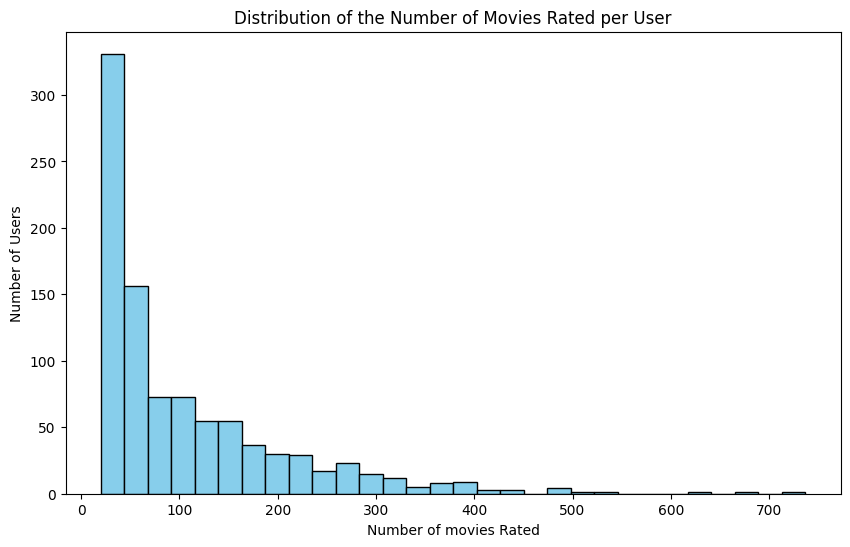

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.hist(user_ratings_count, bins=30, edgecolor='black', color='skyblue')
plt.xlabel('Number of movies Rated')
plt.ylabel('Number of Users')
plt.title('Distribution of the Number of Movies Rated per User')
plt.show()

<div dir="rtl" style="text-align: right;">
### محاسبه تعداد امتیازهای مشترک کاربران (Common Ratings Count)

برای محاسبه میزان شباهت بین دو کاربر، ابتدا باید فیلم‌هایی را شناسایی کنیم که هر دو کاربر به آن‌ها امتیاز داده‌اند.

از آنجا که مقادیر `NaN` نشان‌دهنده نبود امتیاز ثبت‌شده هستند، با استفاده از متد `notna()` و عملگر منطقی `&`، فیلم‌هایی را انتخاب می‌کنیم که هر دو کاربر برای آن‌ها امتیاز ثبت کرده‌اند.

در نهایت، با استفاده از متد `sum()` تعداد فیلم‌های مشترک محاسبه می‌شود.

**نتیجه:** کاربران ۱ و ۲ دارای ۱۸ فیلم مشترک هستند.

**نکته:** تعداد فیلم‌های مشترک یکی از معیارهای ارزیابی میزان قابل‌اعتماد بودن شباهت محاسبه‌شده بین کاربران است.
</div
>

In [11]:
binary_matrix = rating_matrix.notna().astype(int)
print(binary_matrix.shape)
print(binary_matrix.head())
common_ratings_matrix = binary_matrix.dot(binary_matrix.T)
print(common_ratings_matrix.shape)
print(common_ratings_matrix.iloc[:5, :5])

(943, 1682)
item_id  1     2     3     4     5     6     7     8     9     10    ...  \
user_id                                                              ...   
1           1     1     1     1     1     1     1     1     1     1  ...   
2           1     0     0     0     0     0     0     0     0     1  ...   
3           0     0     0     0     0     0     0     0     0     0  ...   
4           0     0     0     0     0     0     0     0     0     0  ...   
5           1     1     0     0     0     0     0     0     0     0  ...   

item_id  1673  1674  1675  1676  1677  1678  1679  1680  1681  1682  
user_id                                                              
1           0     0     0     0     0     0     0     0     0     0  
2           0     0     0     0     0     0     0     0     0     0  
3           0     0     0     0     0     0     0     0     0     0  
4           0     0     0     0     0     0     0     0     0     0  
5           0     0     0     0    